In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import torch

from energia.dataset import cargar_datos_modelo
from energia.entrenamiento import (fijar_semilla, dispositivo, contar_parametros, entrenar, predecir,
                                   guardar_modelo, guardar_resultados)
from energia.metricas import evaluar, error_por_hora, naive_estacional, tabla
from energia.modelos import tcn
from energia.visualizacion import estilo, guardar_figura, curvas_aprendizaje, pronostico_vs_real

estilo()
NOMBRE = "tcn"
fijar_semilla()
print("torch", torch.__version__, "| dispositivo:", dispositivo())

torch 2.5.1+cpu | dispositivo: cpu


In [2]:
datos = cargar_datos_modelo()
datos.resumen()

,muestras,pasado,futuro,y,primer_t0,ultimo_t0
split,,,,,,
train,30265,"(30265, 168, 16)","(30265, 24, 9)","(30265, 24, 2)",2022-01-16,2025-06-30
val,184,"(184, 168, 16)","(184, 24, 9)","(184, 24, 2)",2025-07-01,2025-12-31
test,243,"(243, 168, 16)","(243, 24, 9)","(243, 24, 2)",2026-01-01,2026-08-31


In [3]:
HP_MODELO = {"canales": 32, "kernel": 3, "niveles": 6, "dropout": 0.1, "cabeza": 64}
HP_ENTRENAMIENTO = {"optimizador": "adam", "lr": 1e-3, "epocas": 50, "batch": 256, "paciencia": 8, "clip": 1.0}

modelo = tcn.construir(datos, **HP_MODELO)
print(modelo)
print("parámetros entrenables:", contar_parametros(modelo))

TCNPronostico(
  (tcn): Sequential(
    (0): BloqueResidual(
      (bloque): Sequential(
        (0): ConvCausal(
          (conv): Conv1d(16, 32, kernel_size=(3,), stride=(1,), padding=(2,))
        )
        (1): ReLU()
        (2): Dropout(p=0.1, inplace=False)
        (3): ConvCausal(
          (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(2,))
        )
        (4): ReLU()
        (5): Dropout(p=0.1, inplace=False)
      )
      (atajo): Conv1d(16, 32, kernel_size=(1,), stride=(1,))
    )
    (1): BloqueResidual(
      (bloque): Sequential(
        (0): ConvCausal(
          (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(4,), dilation=(2,))
        )
        (1): ReLU()
        (2): Dropout(p=0.1, inplace=False)
        (3): ConvCausal(
          (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(4,), dilation=(2,))
        )
        (4): ReLU()
        (5): Dropout(p=0.1, inplace=False)
      )
      (atajo): Identity()
    )
    (2): 

In [4]:
historial = entrenar(modelo, datos, **HP_ENTRENAMIENTO)

época   1 | train 0.2557 | val 0.1838 | 315.3 s *
época   2 | train 0.1031 | val 0.1545 | 312.3 s *
época   3 | train 0.0836 | val 0.1639 | 286.9 s
época   4 | train 0.0748 | val 0.1669 | 292.9 s
época   5 | train 0.0693 | val 0.1611 | 283.9 s
época   6 | train 0.0651 | val 0.1739 | 230.3 s
época   7 | train 0.0619 | val 0.1875 | 228.4 s
época   8 | train 0.0589 | val 0.1884 | 242.1 s
época   9 | train 0.0562 | val 0.2181 | 208.6 s
época  10 | train 0.0535 | val 0.2042 | 203.6 s
Early stopping: 8 épocas sin mejorar en validación.


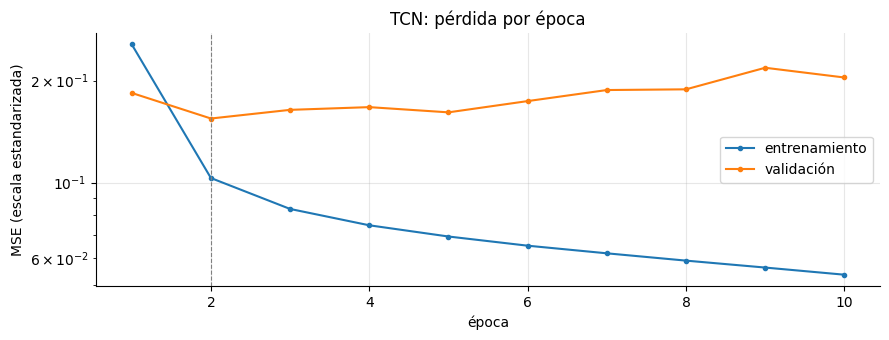

,train,val,segundos
epoca,,,
2,0.103142,0.154532,312.320509


In [5]:
fig = curvas_aprendizaje(historial, "TCN: pérdida por época")
guardar_figura(fig, "f2_02_tcn_curvas")
plt.show()
historial.loc[[historial["val"].idxmin()]]

In [6]:
resultados = {}
predicciones = {}
for split in ["val", "test"]:
    y = datos.y_original(split)
    predicciones[split] = predecir(modelo, datos, split)
    resultados[("tcn", split)] = evaluar(y, predicciones[split])
    resultados[("naive_m24", split)] = evaluar(y, naive_estacional(datos, split, m=24))
    resultados[("naive_m168", split)] = evaluar(y, naive_estacional(datos, split, m=168))

metricas = tabla(resultados)
metricas.index = pd.MultiIndex.from_tuples(metricas.index, names=["modelo", "split"])
metricas.sort_index()

demanda_MAE  precio_MAE   demanda_RMSE  precio_RMSE  \
modelo     split                                                          
naive_m168 test   121128.936093  126.488172  201826.283211   182.248794   
           val    111762.365881   81.734684  179377.523882   136.076668   
naive_m24  test   194816.646206   56.109531  273062.870794   111.123112   
           val    194135.892010   48.523627  274407.867423   111.794765   
tcn        test    83669.607575   83.128932  105278.606320   123.345843   
           val     73562.926390   57.719759   99820.990941   102.132798   

                  demanda_MAPE_%  precio_MAPE_%  demanda_R2  precio_R2  
modelo     split                                                        
naive_m168 test         4.059732      34.665457    0.491508   0.680121  
           val          3.833292      37.448509    0.540316   0.223636  
naive_m24  test         6.670997      14.863168    0.069204   0.881077  
           val          6.718642      20.336838   -0.075762   0.475988  
tcn        test         2.742933      20.677231    0.861640   0.853477  
           val          2.487841      27.431729    0.857647   0.562650

In [7]:
metricas.loc[(slice(None), "val"), ["demanda_MAPE_%", "precio_MAPE_%", "demanda_MAE", "precio_MAE"]]

,,demanda_MAPE_%,precio_MAPE_%,demanda_MAE,precio_MAE
modelo,split,,,,
tcn,val,2.487841,27.431729,73562.926390,57.719759
naive_m24,val,6.718642,20.336838,194135.892010,48.523627
naive_m168,val,3.833292,37.448509,111762.365881,81.734684


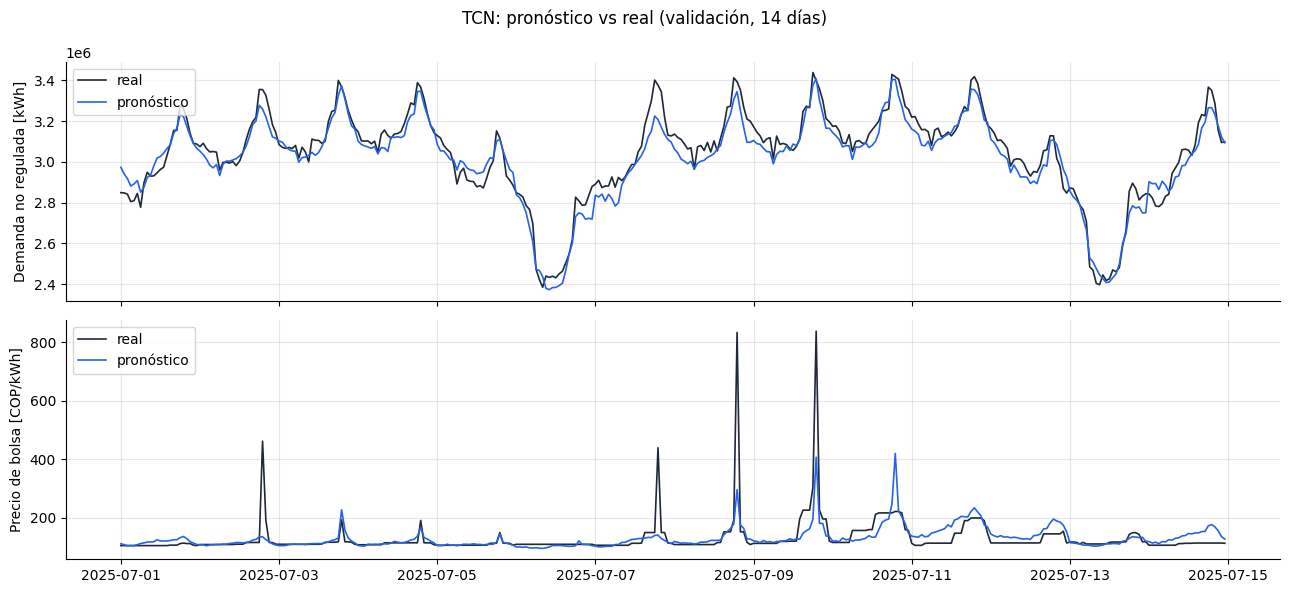

In [8]:
fig = pronostico_vs_real(datos, predicciones["val"], "val", dias=14, titulo="TCN: pronóstico vs real (validación, 14 días)")
guardar_figura(fig, "f2_02_tcn_pronostico_val")
plt.show()

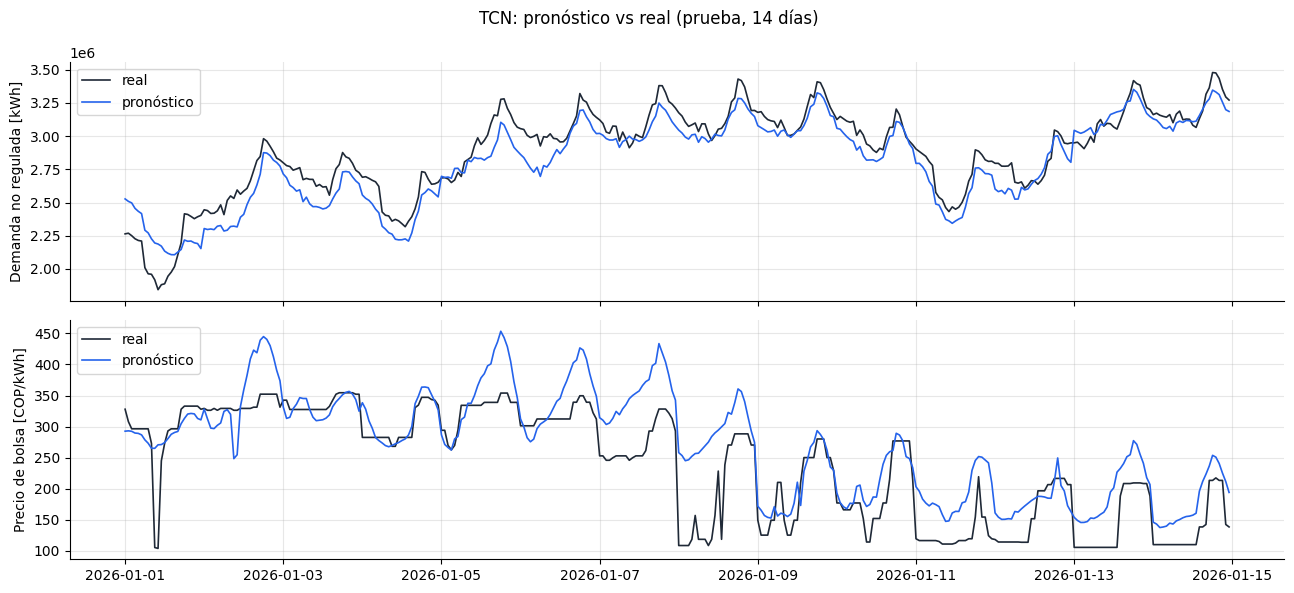

In [9]:
fig = pronostico_vs_real(datos, predicciones["test"], "test", dias=14, titulo="TCN: pronóstico vs real (prueba, 14 días)")
guardar_figura(fig, "f2_02_tcn_pronostico_test")
plt.show()

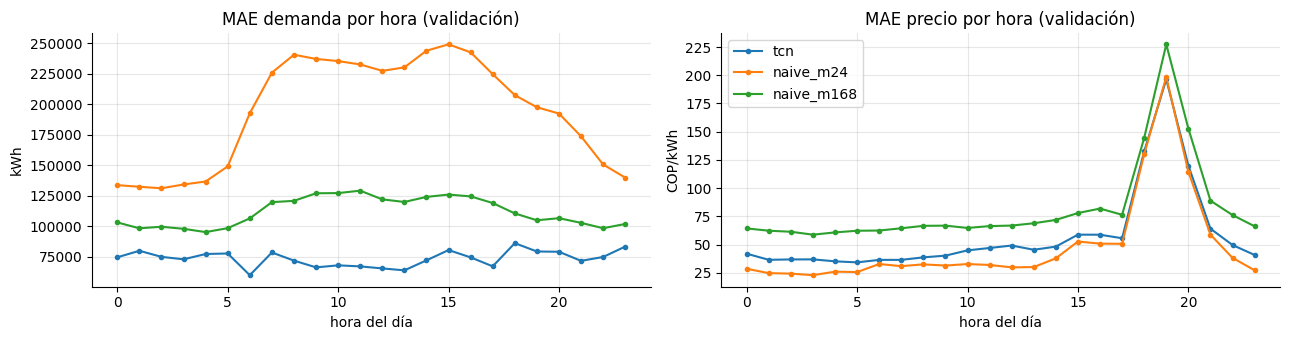

In [10]:
y_val = datos.y_original("val")
errores = {
    "tcn": error_por_hora(y_val, predicciones["val"]),
    "naive_m24": error_por_hora(y_val, naive_estacional(datos, "val", m=24)),
    "naive_m168": error_por_hora(y_val, naive_estacional(datos, "val", m=168)),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for nombre, e in errores.items():
    axes[0].plot(e.index - 1, e["demanda"], marker=".", label=nombre)
    axes[1].plot(e.index - 1, e["precio"], marker=".", label=nombre)
axes[0].set(title="MAE demanda por hora (validación)", xlabel="hora del día", ylabel="kWh")
axes[1].set(title="MAE precio por hora (validación)", xlabel="hora del día", ylabel="COP/kWh")
axes[1].legend()
fig.tight_layout()
guardar_figura(fig, "f2_02_tcn_error_por_hora")
plt.show()

In [11]:
hiperparametros = {**HP_MODELO, **HP_ENTRENAMIENTO, "parametros": contar_parametros(modelo),
                   "mejor_epoca": int(historial["val"].idxmin()), "epocas_entrenadas": len(historial)}
print(guardar_modelo(modelo, NOMBRE, hiperparametros))
print(guardar_resultados(NOMBRE, metricas, hiperparametros, historial))

C:\Users\57310\Desktop\pronostico-energia-nr\pronostico-energia-nr\results\modelos\tcn.pt
C:\Users\57310\Desktop\pronostico-energia-nr\pronostico-energia-nr\results\fase2\tcn
